# Analiză interactivă folosind Jupyter
# Denis Zabolotnii
## Introducere

În această analiză folosim datele despre cărțile unei biblioteci pentru a identifica
diferențele dintre numărul de titluri disponibile într-o secțiune și numărul total
de împrumuturi.

Scopul este să vedem care secțiune are cea mai mare cerere raportată la numărul
de titluri disponibile. Rezultatul poate ajuta biblioteca să identifice secțiunile
care necesită o analiză suplimentară a colecției.

In [21]:
# Importăm biblioteca pandas pentru lucrul cu date tabelare
import pandas as pd
import matplotlib.pyplot as plt

# Încărcăm datele din fișierul CSV
df = pd.read_csv('books.csv')

# Afișăm primele rânduri pentru a verifica datele
df.head()

,catalog_position,title,author,year_published,genre,section,total_copies,times_borrowed,last_borrowed_date,rating,ratings_count,price,language,page_count,dimensions_width,dimensions_thickness,dimensions_height,catalog_shelf,catalog_row,catalog_row_number
0,A1-B1-0001,Enormous Room,E. E. Cummings,1949.0,Drama,Fiction,5.0,3.0,1/6/2025,4.14,2.0,14.66,en,249.0,4.98,0.60,7.97,A1,B1,1
1,A1-B1-0002,Plutarchi Vitae parallelae,Plutarch,1478.0,Biography & Autobiography,History,4.0,1.0,3/19/2024,NaN,NaN,9.99,en,241.0,5.74,1.12,8.08,A1,B1,2
2,A1-B1-0003,The water-babies,Charles Kingsley,1863.0,Fantasy,Children,6.0,6.0,6/5/2024,4.21,6.0,13.89,en,228.0,7.70,0.70,5.10,A1,B1,3
3,A1-B1-0004,Kipps,H. G. Wells,1900.0,Comedy,Fiction,4.0,5.0,11/6/2024,4.44,4.0,370.00,en,386.0,5.08,0.98,7.80,A1,B1,4
4,A1-B1-0005,Man and Superman,George Bernard Shaw,1903.0,Drama,Fiction,5.0,2.0,1/16/2025,4.46,2.0,10.99,en,220.0,5.08,1.22,7.80,A1,B1,5


## Verificarea datelor

Înainte de analiză verificăm structura tabelului și tipurile de date.
Acest pas ne ajută să ne asigurăm că fișierul a fost încărcat corect.

In [22]:
# Afișăm informații despre coloane și tipurile de date
df.info()

# Verificăm dimensiunea setului de date
print("Număr de rânduri și coloane:", df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 2090 entries, 0 to 2089
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   catalog_position      2090 non-null   str    
 1   title                 2090 non-null   str    
 2   author                2090 non-null   str    
 3   year_published        2086 non-null   float64
 4   genre                 2039 non-null   str    
 5   section               2032 non-null   str    
 6   total_copies          2077 non-null   float64
 7   times_borrowed        2084 non-null   float64
 8   last_borrowed_date    2074 non-null   str    
 9   rating                1766 non-null   float64
 10  ratings_count         1762 non-null   float64
 11  price                 1879 non-null   float64
 12  language              2087 non-null   str    
 13  page_count            2085 non-null   float64
 14  dimensions_width      2090 non-null   float64
 15  dimensions_thickness  2089 non-n

## Analiza pe secțiuni

Grupăm cărțile după secțiunea bibliotecii. Pentru fiecare secțiune calculăm:

- numărul de titluri;
- numărul total de împrumuturi;
- raportul dintre împrumuturi și numărul de titluri.

Un raport mai mare înseamnă că, în medie, titlurile din acea secțiune sunt
împrumutate mai des.

In [23]:
# Grupăm datele după secțiune
inventory_gap = df.groupby('section').agg({
    'title': 'count',
    'times_borrowed': 'sum'
})

# Calculăm raportul dintre împrumuturi și numărul de titluri
inventory_gap['titles_to_borrow_ratio'] = (
    inventory_gap['times_borrowed'] / inventory_gap['title']
)

# Sortăm secțiunile descrescător după raport
inventory_gap = inventory_gap.sort_values(
    by='titles_to_borrow_ratio',
    ascending=False
)

inventory_gap

,title,times_borrowed,titles_to_borrow_ratio
section,,,
Young Adult (YA),48,10184.0,212.166667
Young Adult,20,3448.0,172.400000
Non-Fiction,215,21595.0,100.441860
Fiction,1148,48570.0,42.308362
Science,28,992.0,35.428571
Children,212,5753.0,27.136792
Children's,23,478.0,20.782609
Reference,52,718.0,13.807692
History,39,522.0,13.384615


## Rezultatul principal

Pe baza calculului, secțiunea cu cel mai mare raport dintre împrumuturi și numărul
de titluri este **Young Adult (YA)**.

Această secțiune are **48 titluri** și **10184 împrumuturi**,
rezultând un raport de aproximativ **212.17 împrumuturi per titlu**.

Acest rezultat indică faptul că titlurile din această secțiune au cea mai mare
cerere medie dintre secțiunile analizate.

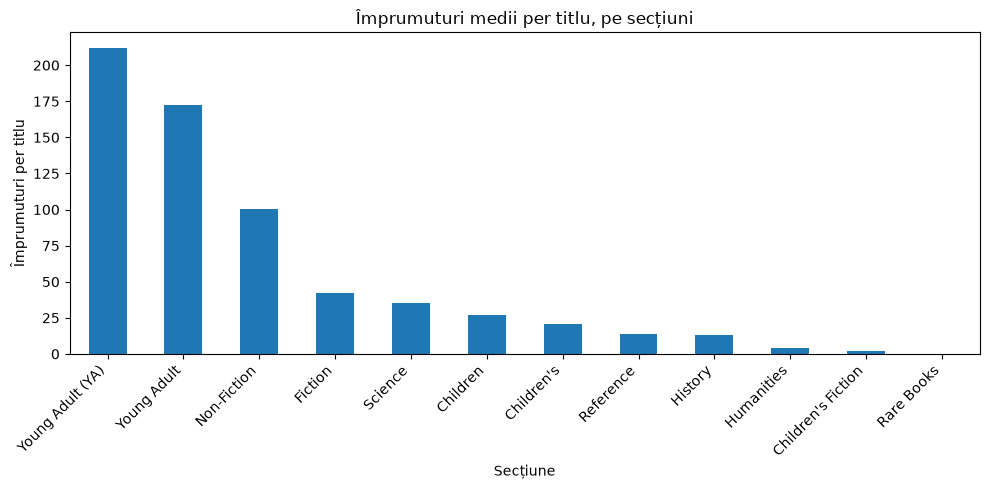

In [24]:
# Reprezentăm grafic raportul calculat pentru fiecare secțiune
ax = inventory_gap['titles_to_borrow_ratio'].plot(
    kind='bar',
    figsize=(10, 5),
    title='Împrumuturi medii per titlu, pe secțiuni'
)

ax.set_xlabel('Secțiune')
ax.set_ylabel('Împrumuturi per titlu')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Concluzie

Analiza arată că **Young Adult (YA)** are cel mai mare dezechilibru dintre cerere și
numărul de titluri disponibile, conform indicatorului folosit în această sarcină.

Un raport ridicat sugerează o cerere mare raportată la dimensiunea colecției.
Biblioteca ar putea folosi această informație pentru a verifica dacă în această
secțiune este nevoie de mai multe exemplare sau de titluri suplimentare.

## Reflecție personală

Consider că rezultatul este util deoarece transformă datele brute într-o informație
ușor de interpretat. Un pas următor logic ar fi să analizăm evoluția împrumuturilor
în timp și să identificăm titlurile individuale cu cea mai mare cerere.

Un alt grafic, de exemplu unul care compară direct numărul de titluri cu numărul
de împrumuturi, ar putea completa această analiză și ar oferi echipei bibliotecii
o imagine mai clară asupra priorităților.